# EPO

> Remove the directions in which the Bruker and Thermo spectra of the same soils differ, by external parameter orthogonalisation, then train on OSSL and predict Fukushima

In [ ]:
#| default_exp epo

In [ ]:
#| export
import numpy as np

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from fastcore.test import *
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from soilspecdata.all import load_ossl
from soilspecdl.all import get_splitter
from ossl_fuku_transfer.data import *
from ossl_fuku_transfer.transfer import *
from ossl_fuku_transfer.inside import layer_features, probe
from sklearn.neighbors import NearestNeighbors

/Users/franckalbinet/pro/dev/soilspec/ossl-fuku-transfer/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


`12_wetchem` found that the OSSL models predict OSSL soils with properties like the Fukushima soils well, and the Fukushima spectra poorly. The failure lies in the spectra. External parameter orthogonalisation (EPO; Roger et al. 2003) removes from every spectrum the directions in which spectra of the same samples differ between two measurement conditions. Here the two conditions are the Bruker and Thermo instruments of `05_paired`, with whatever sample preparation each used.

The module part uses small random arrays, so it runs without the data. The sections from *Paired spectra* onwards read OSSL and the Fukushima data, and are marked `#| fukudata`.

## Projection

`epo_basis` takes the spectra of the same samples under two conditions, and returns the first `k` right singular vectors of their differences, one column per direction. The differences are not centred, so the mean difference between the conditions is part of what the directions capture. `epo_project` removes those directions from spectra:

In [ ]:
#| export
def epo_basis(
    Xa, # Spectra under one condition, one row per sample
    Xb, # Spectra of the same samples under the other condition
    k, # Number of directions
)->np.ndarray: # One unit column per direction, shape (wavenumbers, k)
    "The first `k` right singular vectors of `Xa - Xb`"
    return np.linalg.svd(Xa - Xb, full_matrices=False)[2][:k].T

def epo_project(
    X, # Spectra, one row per sample
    V, # Directions from `epo_basis`
)->np.ndarray:
    "`X` with the directions `V` removed"
    return X - (X @ V) @ V.T

In [ ]:
rng = np.random.default_rng(0)
Xa = rng.normal(size=(50, 30))
Xb = Xa + np.outer(rng.normal(size=50), np.r_[1., np.zeros(29)])
V = epo_basis(Xa, Xb, 1)
test_close(np.abs(V[:, 0]), np.r_[1., np.zeros(29)], eps=1e-8)
test_close(epo_project(Xa, V) @ V, 0, eps=1e-8)
test_close(epo_project(epo_project(Xa, V), V), epo_project(Xa, V), eps=1e-8)
test_close(epo_project(Xa, V), epo_project(Xb, V), eps=1e-8)

## Paired spectra

The paired soils of `05_paired`, without those in the Fukushima test set, so no test spectrum enters the correction. Both instruments' spectra get SNV and the Savitzky-Golay first derivative. The Bruker exports end at 3996 cm⁻¹, one point short of the shared grid, so the directions are estimated on 650–3996 cm⁻¹ and the projection leaves the last point, 3998 cm⁻¹, unchanged:

In [ ]:
#| fukudata
pw = shared_wns[:-1]
_, test_ids = cs137_split()
ids = [i for i in sorted(set(bruker_files()) & set(spa_files()), key=int) if i not in excluded and i not in set(test_ids)]
br, th = load_bruker(pw, ids), load_fuku(pw, ids)
pipe = preprocessings()['snv_d1']
Xb_p, Xt_p = pipe.fit_transform(br.spectra), pipe.fit_transform(th.spectra)
s = np.linalg.svd(Xt_p - Xb_p, compute_uv=False)
share = s**2 / (s**2).sum()
basis = lambda k: np.vstack([epo_basis(Xt_p, Xb_p, k), np.zeros((1, k))])
len(ids), pd.Series(share.cumsum()[[0, 1, 3, 7, 15, 31]], index=[1, 2, 4, 8, 16, 32], name='cumulative share').round(3).to_dict()

(365, {1: 0.795, 2: 0.838, 4: 0.887, 8: 0.935, 16: 0.964, 32: 0.984})

The first four directions, against wavenumber:

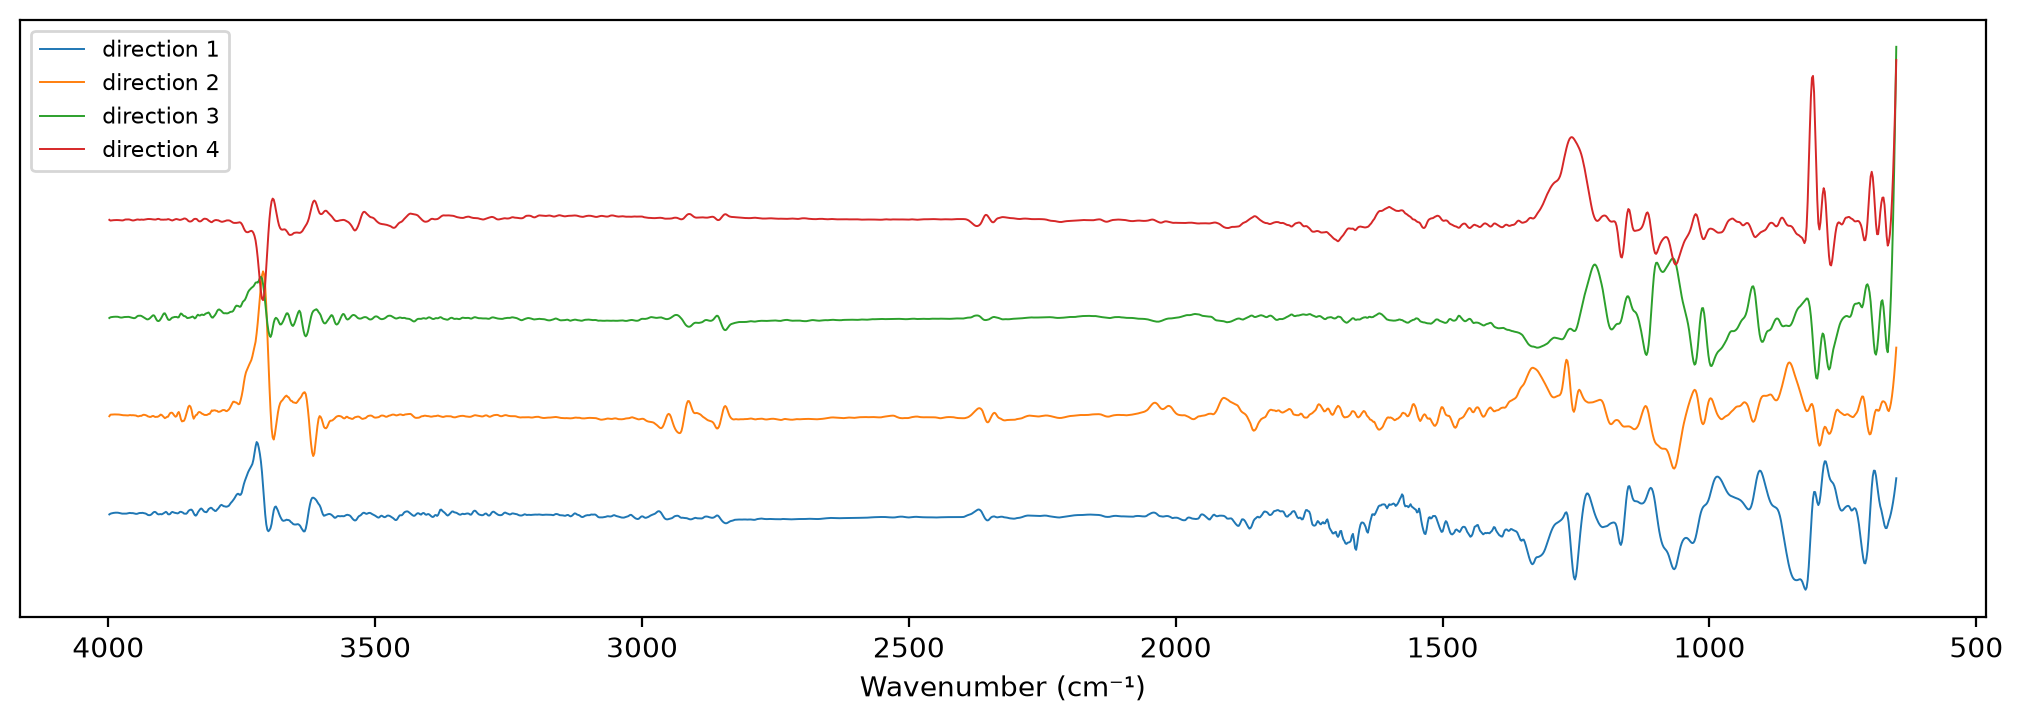

In [ ]:
#| fukudata
fig, ax = plt.subplots(figsize=(10, 3.5), layout='constrained')
for j, v in enumerate(basis(4).T): ax.plot(shared_wns, v + 0.15 * j, lw=0.7, label=f'direction {j + 1}')
ax.invert_xaxis(); ax.set_xlabel('Wavenumber (cm⁻¹)'); ax.set_yticks([]); ax.legend(fontsize=8);

## Linear check

Before training a CNN, a ridge regression shows whether EPO helps at all. It trains on 20,000 random OSSL spectra with the target, after removing the first `k` directions, and predicts zero-shot the Fukushima spectra with the same directions removed, and 5,000 other OSSL spectra as a check that EPO keeps what OSSL needs. `k = 0` is no correction. The Fukushima scores are on the training samples, which choose `k`, and on the test samples:

In [ ]:
#| fukudata
om = load_ossl().mir(wmin=shared_wns[0], wmax=shared_wns[-1])
fuku = load_fuku()
fuku.source = fuku.source.assign(Kex=fuku.source['soil_ex_K2O'] / mg_k2o_per_cmolc, CEC=fuku.source['soil_CEC'])
r = np.random.default_rng(0)
data = {}
for t, col in (('Kex', 'k.ext_usda.a725_cmolc.kg'), ('CEC', 'cec_usda.a723_cmolc.kg')):
    Xo, yo, ido = om.xy(col)
    Xf, yf, idf = fuku.xy(t)
    perm = r.permutation(len(Xo))
    data[t] = dict(Xo=pipe.fit_transform(Xo), yo=np.log1p(yo.ravel()), ido=ido, Xf=pipe.transform(Xf), yf=np.log1p(yf.ravel()),
                   is_test=np.isin(idf, test_ids), tr=perm[:20000], va=perm[20000:25000])

def zero_shot(t, V=None):
    "Scores of a ridge regression trained on OSSL for target `t`, with the directions `V` removed, or none if None"
    d = data[t]
    P = (lambda X: X) if V is None else (lambda X: epo_project(X, V))
    m = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-1, 6, 15))).fit(P(d['Xo'][d['tr']]), d['yo'][d['tr']])
    pf = m.predict(P(d['Xf']))
    res = {'OSSL R²': scores(d['yo'][d['va']], m.predict(P(d['Xo'][d['va']])))['R²']}
    for s, msk in (('train', ~d['is_test']), ('test', d['is_test'])):
        sc = scores(d['yf'][msk], pf[msk])
        res |= {f'Fukushima {s} R²': sc['R²'], f'Fukushima {s} r': sc['r']}
    return res

ks = [0, 1, 2, 4, 8, 16, 32]
lin = pd.DataFrame([{'target': t, 'k': k, **zero_shot(t, None if k == 0 else basis(k))} for t in data for k in ks]).set_index(['target', 'k'])
lin.round(3)

OSSL R²  ...  Fukushima test r
target k            ...                  
Kex    0     0.652  ...             0.040
       1     0.651  ...             0.039
       2     0.652  ...             0.040
       4     0.652  ...            -0.029
       8     0.655  ...            -0.045
       16    0.655  ...            -0.078
       32    0.649  ...            -0.089
CEC    0     0.956  ...             0.474
       1     0.957  ...             0.354
       2     0.957  ...             0.431
       4     0.957  ...             0.487
       8     0.957  ...             0.400
       16    0.957  ...             0.400
       32    0.957  ...             0.428

[14 rows x 5 columns]

## Analogue EPO

The paired Bruker spectra fail with the OSSL models too, so correcting towards them cannot work. The soil analogues of `12_wetchem` give pairs with OSSL itself: each Fukushima soil and the OSSL sample with the closest properties. The two soils of a pair are not the same, so their spectral differences mix soil variation with the difference in measurement. Over many pairs, the measurement difference is systematic and should dominate the first directions.

For each target, the pairs use only the Fukushima training samples, and OSSL samples outside that target's 5,000 check samples. The matching is that of `12_wetchem`: nearest neighbour in the seven standardised properties of `prop_features`. Then the same ridge regressions as above, with the analogue directions removed:

In [ ]:
#| fukudata
op, fp = prop_features(ossl_shared_props(om)), prop_features(fuku_shared_props(fuku.sample_ids))
sc_p = StandardScaler().fit(op)
opos = pd.Series(np.arange(len(om.sample_ids)), index=om.sample_ids)
fpos = pd.Series(np.arange(len(fuku.sample_ids)), index=fuku.sample_ids)
f_train = fp.index[~np.isin(fp.index, test_ids)]
Xf_all = pipe.transform(fuku.spectra)
pairs, abasis = {}, {}
for t, d in data.items():
    pool = op.index.difference(d['ido'][d['va']])
    nn = NearestNeighbors(n_neighbors=1).fit(sc_p.transform(op.loc[pool]))
    an = pool[nn.kneighbors(sc_p.transform(fp.loc[f_train]))[1][:, 0]]
    Xa_f, Xa_o = Xf_all[fpos[f_train].to_numpy()], pipe.transform(om.spectra[opos[an].to_numpy()])
    sv = np.linalg.svd(Xa_f - Xa_o, compute_uv=False)
    pairs[t] = {'pairs': len(f_train), 'distinct analogues': len(np.unique(an)), 'share of direction 1': (sv[0]**2 / (sv**2).sum()), 'share of 8': (sv[:8]**2).sum() / (sv**2).sum()}
    abasis[t] = lambda k, Xa_f=Xa_f, Xa_o=Xa_o: epo_basis(Xa_f, Xa_o, k)
pd.DataFrame(pairs).round(3)

,Kex,CEC
pairs,1045.000,1045.000
distinct analogues,685.000,694.000
share of direction 1,0.684,0.679
share of 8,0.914,0.915


In [ ]:
#| fukudata
alin = pd.DataFrame([{'target': t, 'k': k, **zero_shot(t, None if k == 0 else abasis[t](k))} for t in data for k in ks]).set_index(['target', 'k'])
alin.round(3)

OSSL R²  ...  Fukushima test r
target k            ...                  
Kex    0     0.652  ...             0.040
       1     0.652  ...             0.033
       2     0.653  ...             0.003
       4     0.654  ...            -0.055
       8     0.652  ...             0.097
       16    0.656  ...             0.061
       32    0.655  ...             0.068
CEC    0     0.956  ...             0.474
       1     0.957  ...             0.446
       2     0.957  ...             0.487
       4     0.957  ...             0.507
       8     0.957  ...             0.497
       16    0.956  ...             0.325
       32    0.956  ...             0.305

[14 rows x 5 columns]

## Findings

EPO with the paired Bruker and Thermo spectra doesn't make OSSL models transfer to Fukushima. With a ridge regression trained on OSSL, the zero-shot correlation for Fukushima Kex stays between −0.09 and 0.04 for every number of removed directions from 0 to 32, on the training and the test samples. For CEC it varies between 0.35 and 0.55 without a consistent gain over no correction (0.50 on the training samples, 0.47 on the test samples). The OSSL validation R² stays at 0.65 for Kex and 0.96 for CEC, so the projection keeps what OSSL needs, but it doesn't fix Fukushima. All Fukushima R² values are negative, from large biases.

The 365 paired soils give a clear structure: the first direction holds 80% of the squared differences, and 8 directions hold 94%.

A likely reason is in `05_paired`. The OSSL Kex model fails on the Bruker spectra of these soils too (correlation 0.19). EPO removes how the Thermo spectra differ from these Bruker spectra. Even a perfect correction would only bring the Thermo spectra to the Bruker spectra, which are themselves not like OSSL's for Kex. The Bruker instrument and preparation behind these exports are not known, and may differ from those of the KSSL spectra in OSSL.

EPO from the soil analogues doesn't fix the transfer either. Its 1,045 pairs per target use about 690 distinct OSSL analogues. The first direction holds 68% of the squared differences, and 8 directions hold 91%. Removing them reduces the Kex bias: the Fukushima R² rises from −20 to −22 without correction to between −2 and −3 for 4 directions or more. The correlation stays low: at most 0.16 on the training samples and 0.10 on the test samples. For CEC, 4 directions give the best correlation, 0.55 on the training samples and 0.51 on the test samples, against 0.50 and 0.47 without correction. More directions lower it.

Neither linear correction, towards the Bruker spectra or towards OSSL analogues, gives the ridge regression a usable zero-shot correlation for Kex. Pretraining the CNN on EPO-projected OSSL spectra was not run, because the linear checks give no reason to expect a gain.

In [ ]:
#| hide
import nbdev; nbdev.nbdev_export()